# RQ2: Does reliance on help fade with practice, and differently for students who later struggle?

**Early Help-Seeking Transitions · LA group project · RQ2 analysis on the RQ1 handoff (k = 7)**

This notebook answers RQ2 using exactly what RQ1 handed over: the same seven state labels, the same 7-problem early window, the same 2,830 histories and the same later-performance outcome. Each step explains *why* before the code.

**Analysis flow**

| Step | Section | Purpose |
|---|---|---|
| Data | 0–3 | Load RQ1's handoff, rebuild attempts in time order, keep hint items |
| Measure | 4–5 | Avoid the circularity trap; define reliance shares on stuck problems, early vs later |
| Part 1 of RQ2 | 5b | Does reliance fade within each group? |
| Part 2 of RQ2 | 6–7 | Do strugglers differ at the same starting level? (stratified comparison, rank-based ANCOVA as in RQ1) |
| Checks | 6b, 8, 9 | Heterogeneity across early scores, no problem used twice, pre-specified network test |
| Conclusion | 10 | What we can and cannot claim |

**Design choices relative to the earlier exploratory RQ2 analysis**

| | Exploratory analysis | This notebook |
|---|---|---|
| Early window | first 3 problems | first **7** problems (RQ1's choice) |
| Histories | 9,980 (at least 6 problems) | **2,830** (at least 14 problems) |
| Later performance | struggle yes/no | **continuous** later % correct, plus the yes/no label for easy reading |
| Main test | group comparison with resampling | **rank-based ANCOVA**, the same family RQ1 uses, plus the group comparison |
| Networks | "strugglers become more repetitive" (exploratory) | the same idea **tested in advance**; it did **not** hold up |

## 0. Setup and loading the handoff safely

RQ1 saved its outputs in one **pickle** file. A pickle can contain instructions that Python runs while loading it, so opening one from someone else is a small security risk. We checked that this file only refers to pandas and numpy, and the loader below **refuses anything else**. It's a good habit with any pickle you didn't make yourself.

**Figures.** Every figure in the report is drawn by a cell in this notebook and saved to `rq2_figures/` under the same name (fig1 to fig12). If the data or a method changes, rerun the notebook and the figures update with it.

In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import f as f_dist

HANDOFF_PATH = "rq1_merged_spm_quade_outputs/rq1_objects_for_rq2_rq3.pkl"   # <- edit if needed

class SafeUnpickler(pickle.Unpickler):
    # Only allow pandas / numpy classes and a few harmless built-ins.
    def find_class(self, module, name):
        if module.split(".")[0] in ("pandas", "numpy") or (module == "builtins" and name in ("slice", "list", "dict", "tuple", "set", "int", "float", "str", "bool", "range")):
            return super().find_class(module, name)
        raise pickle.UnpicklingError(f"Blocked: {module}.{name}")

with open(HANDOFF_PATH, "rb") as fh:
    handoff = SafeUnpickler(fh).load()

import os
FIG_DIR = "rq2_figures"                      # every report figure is saved here by the cell that draws it
os.makedirs(FIG_DIR, exist_ok=True)

# One palette for every chart: blue = no later struggle, orange = later struggle,
# blue ramp = less help -> more help, black/grey = estimates and neutral elements.
C = {0: "#2a78d6", 1: "#eb6834"}
COLORS = C
LABELS = {0: "No later struggle", 1: "Later struggle"}
RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "legend.frameon": False, "lines.linewidth": 2,
})

def save_fig(fig, name, note=None):
    # Add a footnote, save the PNG used in the report, and leave the figure open so it shows below the cell.
    if note:
        fig.text(0.01, -0.045, note, fontsize=9, color=INK2, ha="left", va="top")
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")

def boot_mean(df, col, n_boot=2000, seed=612):
    # Mean of `col` with a 95% range from resampling whole students (one student can have several skills).
    rng = np.random.default_rng(seed)
    students = df.userId.unique(); u = pd.Series(np.arange(len(students)), index=students)[df.userId].to_numpy()
    W = rng.multinomial(len(students), np.full(len(students), 1 / len(students)), size=n_boot)
    tot = W @ np.bincount(u, weights=df[col].to_numpy(), minlength=len(students))
    n = W @ np.bincount(u, minlength=len(students))
    lo, hi = np.percentile(tot / n, [2.5, 97.5])
    return df[col].mean(), lo, hi

pd.set_option("display.precision", 3)
print("Objects in the handoff:", list(handoff))

Objects in the handoff: ['episode', 'k3_population', 'k3_transitions', 'k3_transition_counts', 'opt_population', 'opt_transitions', 'opt_transition_counts', 'opt_model', 'window_selection', 'window_diagnostics', 'state_order', 'all_transitions', 'selected_k', 'alpha', 'random_seed']


## 1. What RQ1 handed over

- `selected_k`: the early window length RQ1 chose (7).
- `opt_population`: one row per eligible history, with the later outcome and the early covariates RQ1 adjusts for.
- `episode`: one row per problem attempt for every student, with its seven-state label.

These numbers should match RQ1 exactly: **2,830 histories, 25.5% later struggle**.

In [2]:
K = handoff["selected_k"]
pop = handoff["opt_population"].copy()
episode = handoff["episode"].copy()

print(f"Early window: first {K} problems")
print(f"{len(pop):,} histories from {pop.userId.nunique():,} students")
print(f"Later struggle (below 50% later correct): {pop.later_struggle.mean():.1%}")
print(f"Mean later % correct: {pop.later_percent_correct.mean():.1f}")
pop[["later_percent_correct", "later_struggle", "early_score", "early_scaffold_share", "mean_early_item_easiness"]].describe().round(2)

Early window: first 7 problems
2,830 histories from 1,406 students
Later struggle (below 50% later correct): 25.5%
Mean later % correct: 64.1


,later_percent_correct,later_struggle,early_score,early_scaffold_share,mean_early_item_easiness
count,2830.00,2830.00,2830.00,2830.00,2830.00
mean,64.15,0.26,3.78,0.09,0.65
std,25.06,0.44,1.95,0.22,0.12
min,0.00,0.00,0.00,0.00,0.18
25%,48.04,0.00,2.00,0.00,0.57
50%,69.10,0.00,4.00,0.00,0.65
75%,85.61,1.00,5.00,0.00,0.73
max,100.00,1.00,7.00,1.00,0.96


`early_score` now runs from 0 to 7: how many of the first 7 problems were right first time. The covariates (`early_scaffold_share`, the problem-format shares, `mean_early_item_easiness`) are exactly the ones RQ1 adjusts for, so we can reuse them.

## 2. Rebuild every attempt in time order

We put each history's problems in order, the same way RQ1's starter does (by start time, then the original row order to break ties), and mark attempts 1–7 as **early** and 8 onward as **later**.

In [3]:
attempts = episode.sort_values(["userId", "skill", "start_time", "episode_row_order"], kind="mergesort").copy()
attempts["skill_attempt"] = attempts.groupby(["userId", "skill"]).cumcount() + 1
attempts = attempts.merge(pop[["userId", "skill", "later_struggle", "later_percent_correct", "early_score"]],
                          on=["userId", "skill"])
attempts["window"] = np.where(attempts.skill_attempt <= K, "early", "later")

check = attempts.groupby(["userId", "skill"]).size().rename("n").reset_index().merge(pop, on=["userId", "skill"])
print("Attempt counts match RQ1:", bool((check.n == check.n_attempts).all()))
print(f"{len(attempts):,} attempts in the {len(pop):,} histories")

Attempt counts match RQ1: True
64,928 attempts in the 2,830 histories


## 3. Hint items only

Some problems give **step-by-step scaffolding** automatically after a wrong answer; others let the student ask for **hints** whenever they like. RQ2 is about the student's *choice* to rely on help, so we keep **hint items only**. A problem counts as a scaffold item if any student ever got scaffolding on it.

In [4]:
scaffold_items = set(episode.loc[episode.any_scaffold == 1, "problemId"])
attempts["hint_item"] = ~attempts.problemId.isin(scaffold_items)
print(f"Hint items: {attempts.hint_item.mean():.1%} of attempts in these histories")

Hint items: 85.7% of attempts in these histories


## 4. The circularity trap

Later strugglers use far more help in their later problems, but that is not a finding. "Later struggle" *means* many later problems wrong first time, and every help state can only happen on a problem that was wrong first time. Raw help use mostly re-describes the outcome.

In [5]:
later = attempts[attempts.window == "later"]
pd.DataFrame({
    "later problems wrong first time": later.groupby("later_struggle").apply(lambda d: (d.state != "CFA").mean(), include_groups=False),
    "later problems involving help": later.groupby("later_struggle").apply(lambda d: d.state.isin(["ERR-HINT", "HINT-FIRST", "BOH", "SCAF-PASS", "SCAF-STRUGGLE"]).mean(), include_groups=False),
}).rename(index=LABELS).round(3)

,later problems wrong first time,later problems involving help
later_struggle,,
No later struggle,0.253,0.124
Later struggle,0.683,0.474


**The fix:** look only at problems the student got wrong ("stuck" problems), and ask what they did: fix it alone, use a hint, click through to the answer, or ask for a hint before trying. The outcome definition says nothing about *that* choice.

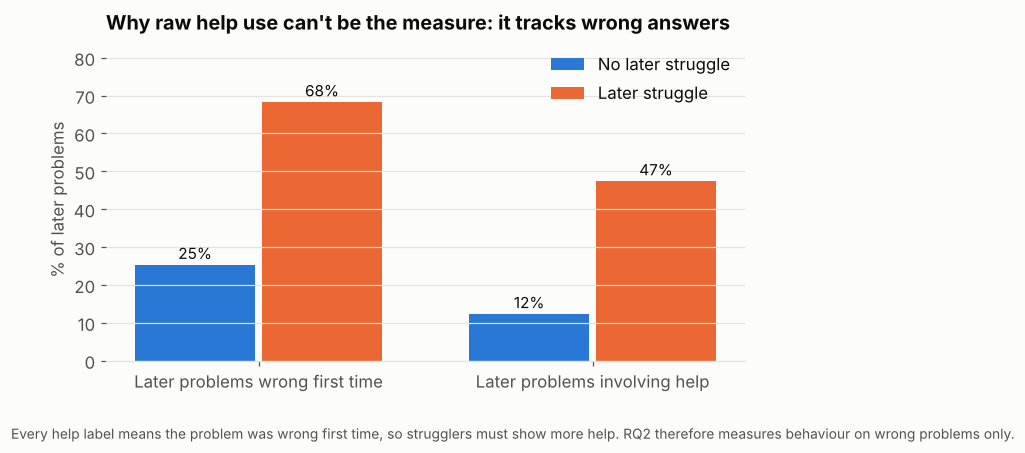

In [6]:
# fig1: the circularity trap, drawn
f1 = pd.DataFrame({
    "wrong": later.groupby("later_struggle").apply(lambda d: (d.state != "CFA").mean(), include_groups=False),
    "help": later.groupby("later_struggle").apply(lambda d: d.state.isin(["ERR-HINT", "HINT-FIRST", "BOH", "SCAF-PASS", "SCAF-STRUGGLE"]).mean(), include_groups=False),
}) * 100
fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(2); w = 0.36
for i, g in enumerate([0, 1]):
    vals = f1.loc[g].to_numpy()
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), vals, w, color=C[g], label=LABELS[g])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.0f}%", ha="center", fontsize=10, color=INK)
ax.set_xticks(x, ["Later problems wrong first time", "Later problems involving help"])
ax.set_ylim(0, 85); ax.set_ylabel("% of later problems"); ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
ax.set_title("Why raw help use can't be the measure: it tracks wrong answers")
save_fig(fig, "fig1_circularity", "Every help label means the problem was wrong first time, so strugglers must show more help. RQ2 therefore measures behaviour on wrong problems only.")

## 5. Two reliance measures, early vs later, within each history

For each history and each window, among its stuck hint-item problems:
- **Answer-clicking share:** how many ended with the bottom-out hint (BOH), the hint that shows the answer.
- **Hint-before-trying share:** how many started with a hint request before any attempt (HINT-FIRST).

Then **change = later share − early share**, computed per history. Each history is compared with *itself*, so long histories can't swamp the average (the pooling trap from the first notebook). A history needs at least one stuck problem in both windows.

In [7]:
stuck = attempts[attempts.hint_item & (attempts.state != "CFA")].copy()
stuck["bottom_out"] = (stuck.state == "BOH").astype(float)
stuck["hint_first"] = (stuck.state == "HINT-FIRST").astype(float)

per_hist = stuck.groupby(["userId", "skill", "window"])[["bottom_out", "hint_first"]].mean().unstack("window").dropna()
per_hist.columns = [f"{m}_{w}" for m, w in per_hist.columns]
per_hist = per_hist.reset_index().merge(pop, on=["userId", "skill"])
per_hist["bottom_out_change"] = per_hist.bottom_out_later - per_hist.bottom_out_early
per_hist["hint_first_change"] = per_hist.hint_first_later - per_hist.hint_first_early

print(f"{len(per_hist):,} of {len(pop):,} histories have stuck problems in both windows "
      f"({per_hist.later_struggle.sum():,} later strugglers, {per_hist.userId.nunique():,} students)")
summary = per_hist.groupby("later_struggle")[["bottom_out_early", "bottom_out_later", "bottom_out_change",
                                               "hint_first_early", "hint_first_later", "hint_first_change"]].mean()
summary.rename(index=LABELS).round(3)

2,095 of 2,830 histories have stuck problems in both windows (587 later strugglers, 1,211 students)


,bottom_out_early,bottom_out_later,bottom_out_change,hint_first_early,hint_first_later,hint_first_change
later_struggle,,,,,,
No later struggle,0.251,0.222,-0.030,0.083,0.064,-0.019
Later struggle,0.415,0.419,0.003,0.115,0.132,0.017


,ERR-SELF_early,ERR-SELF_later,ERR-HINT_early,ERR-HINT_later,HINT-FIRST_early,HINT-FIRST_later,BOH_early,BOH_later
later_struggle,,,,,,,,
No later struggle,51.5,60.2,15.0,11.2,8.3,6.4,25.1,22.2
Later struggle,37.1,35.7,9.9,9.2,11.5,13.2,41.5,41.9


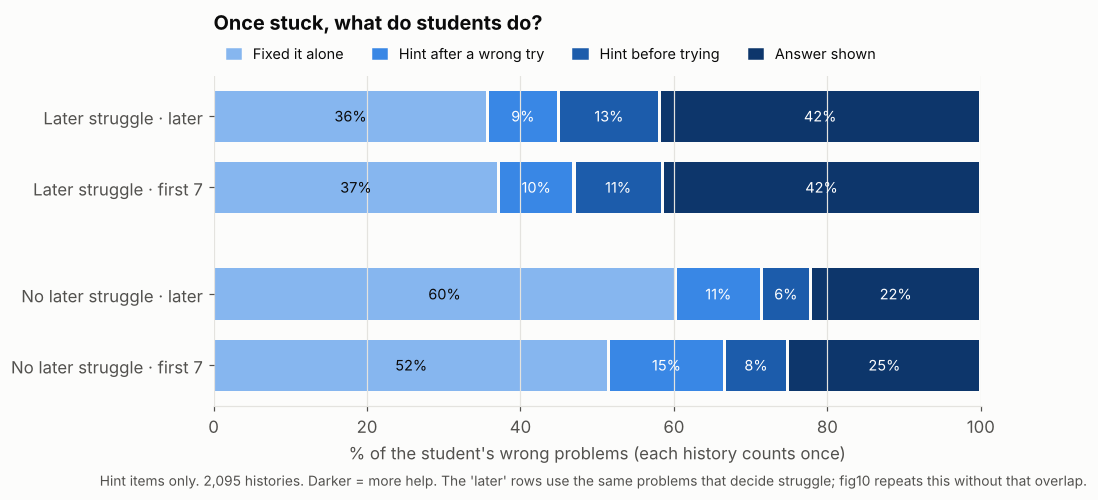

In [8]:
# fig2: once stuck, what do students do? (each history counts once)
STATES = ["ERR-SELF", "ERR-HINT", "HINT-FIRST", "BOH"]
SNAME = {"ERR-SELF": "Fixed it alone", "ERR-HINT": "Hint after a wrong try", "HINT-FIRST": "Hint before trying", "BOH": "Answer shown"}

def state_shares(df, window_col, group_col):
    # Share of each history's stuck problems in each state, per window; then averaged per group.
    d = df.assign(**{st: (df.state == st).astype(float) for st in STATES})
    sh = d.groupby(["userId", "skill", window_col])[STATES].mean().unstack(window_col).dropna()
    sh.columns = [f"{st}_{w}" for st, w in sh.columns]
    sh = sh.reset_index().merge(d.groupby(["userId", "skill"])[group_col].first().reset_index(), on=["userId", "skill"])
    return sh, sh.groupby(group_col)[[c for c in sh.columns if c.split("_")[0] in STATES]].mean() * 100

def composition_chart(comp, rows, ylabels, title, name, note):
    fig, ax = plt.subplots(figsize=(9, 3.9))
    yy = [0, 1, 2.5, 3.5]
    for y, (g, wdw) in zip(yy, rows):
        left = 0
        for st, col in zip(STATES, RAMP):
            v = comp.loc[g, f"{st}_{wdw}"]
            ax.barh(y, v - 0.4, left=left + 0.2, height=0.72, color=col, linewidth=0)
            if v >= 5:
                ax.text(left + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=9.5, color=INK if col == RAMP[0] else "white")
            left += v
    ax.set_yticks(yy, ylabels); ax.set_xlim(0, 100); ax.set_xlabel("% of the student's wrong problems (each history counts once)")
    ax.grid(axis="y", visible=False); ax.invert_yaxis()
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in RAMP]
    ax.legend(handles, [SNAME[st] for st in STATES], ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9.5, handlelength=1)
    ax.set_title(title, pad=30)
    save_fig(fig, name, note)

shares, comp = state_shares(stuck, "window", "later_struggle")
composition_chart(comp, [(1, "later"), (1, "early"), (0, "later"), (0, "early")],
                  [f"{LABELS[g]} · {'later' if w == 'later' else f'first {K}'}" for g, w in [(1, "later"), (1, "early"), (0, "later"), (0, "early")]],
                  "Once stuck, what do students do?", "fig2_what_students_do_when_stuck",
                  f"Hint items only. {len(shares):,} histories. Darker = more help. The 'later' rows use the same problems that decide struggle; fig10 repeats this without that overlap.")
comp.rename(index=LABELS).round(1)

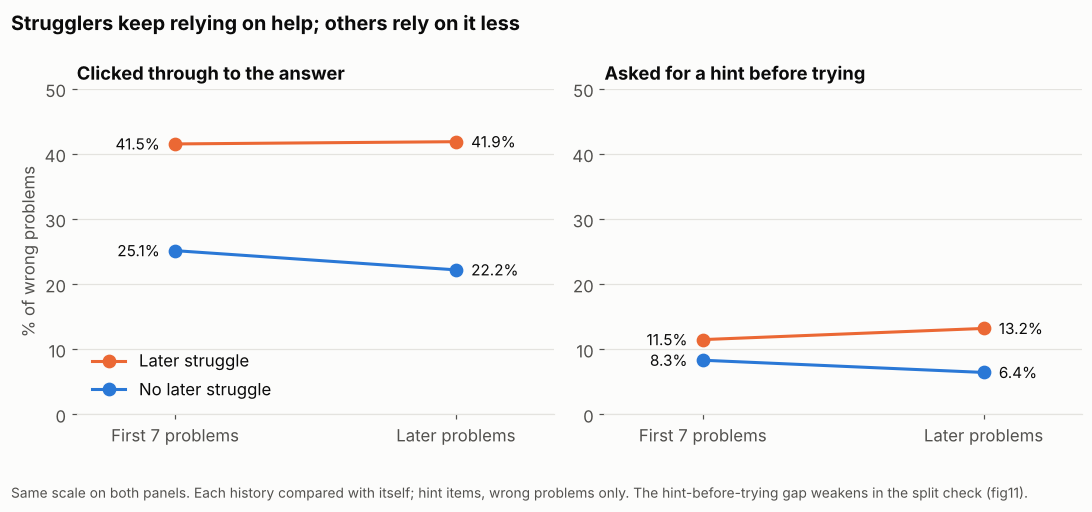

In [9]:
# fig3: early vs later, both measures on the same 0-50 scale
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (m, title) in zip(axes, [("bottom_out", "Clicked through to the answer"), ("hint_first", "Asked for a hint before trying")]):
    for g in [1, 0]:
        d = per_hist[per_hist.later_struggle == g]
        y = [d[f"{m}_early"].mean() * 100, d[f"{m}_later"].mean() * 100]
        ax.plot([0, 1], y, color=C[g], marker="o", markersize=8, label=LABELS[g])
        ax.annotate(f"{y[0]:.1f}%", (0, y[0]), xytext=(-10, 0), textcoords="offset points", ha="right", va="center", fontsize=10)
        ax.annotate(f"{y[1]:.1f}%", (1, y[1]), xytext=(10, 0), textcoords="offset points", ha="left", va="center", fontsize=10)
    ax.set_xticks([0, 1], [f"First {K} problems", "Later problems"]); ax.set_xlim(-0.35, 1.35)
    ax.set_ylim(0, 50); ax.set_title(title, fontsize=12); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% of wrong problems")
axes[0].legend(loc="lower left")
fig.suptitle("Strugglers keep relying on help; others rely on it less", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save_fig(fig, "fig3_slopes", "Same scale on both panels. Each history compared with itself; hint items, wrong problems only. The hint-before-trying gap weakens in the split check (fig11).")

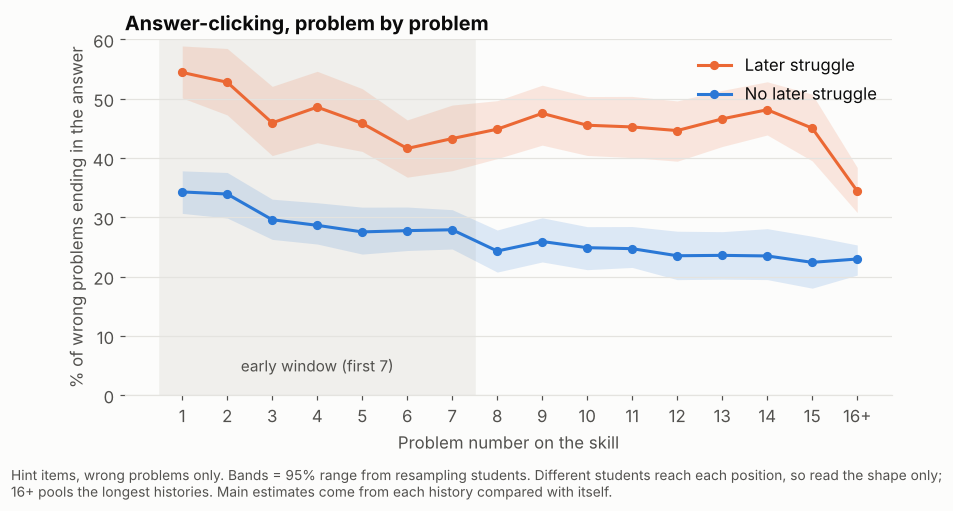

In [10]:
# fig6: answer-clicking problem by problem (descriptive only: different students reach each position)
s2 = stuck.copy(); s2["pos"] = s2.skill_attempt.clip(upper=16)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.axvspan(0.5, K + 0.5, color="#f0efec", zorder=0)
ax.text((K + 1) / 2, 4, f"early window (first {K})", ha="center", color=INK2, fontsize=10)
for g in [1, 0]:
    pts = np.array([[q, *boot_mean(s2[(s2.later_struggle == g) & (s2.pos == q)], "bottom_out", 500)] for q in range(1, 17)])
    ax.fill_between(pts[:, 0], pts[:, 2] * 100, pts[:, 3] * 100, color=C[g], alpha=0.15, lw=0)
    ax.plot(pts[:, 0], pts[:, 1] * 100, color=C[g], marker="o", ms=5, label=LABELS[g])
ax.set_xticks(range(1, 17), [*map(str, range(1, 16)), "16+"])
ax.set_xlabel("Problem number on the skill"); ax.set_ylabel("% of wrong problems ending in the answer")
ax.set_ylim(0, 60); ax.grid(axis="x", visible=False); ax.legend(loc="upper right")
ax.set_title("Answer-clicking, problem by problem")
save_fig(fig, "fig6_problem_by_problem", "Hint items, wrong problems only. Bands = 95% range from resampling students. Different students reach each position, so read the shape only;\n16+ pools the longest histories. Main estimates come from each history compared with itself.")

Students who later struggle **don't reduce** their answer-clicking (about 42% → 42% of wrong problems), while other students do (about 25% → 22%). And strugglers ask for hints before trying *more* over time, while others do it less.

But strugglers also start from a different place, with lower early scores. Before believing the difference, we compare like with like.

### 5b. Part 1 of RQ2: does reliance actually fade, within each group?

The chart shows averages. To answer "does reliance fade with practice?" we need to know whether each group's change is **bigger than chance**. We also add a third row, *fixed it alone* (ERR-SELF), to see what replaced the help when students stopped relying on it.

The 95% range comes from resampling **students**, because one student can contribute several skills.

In [11]:
stuck["fixed_alone"] = (stuck.state == "ERR-SELF").astype(float)
fa = stuck.groupby(["userId", "skill", "window"]).fixed_alone.mean().unstack("window").dropna()
per_hist = per_hist.merge((fa["later"] - fa["early"]).rename("fixed_alone_change").reset_index(), on=["userId", "skill"])

def mean_change(df, col):
    m, lo, hi = boot_mean(df, col)            # helper from section 0
    return f"{100 * m:+.1f} [{100 * lo:.1f}, {100 * hi:.1f}]"

rows = []
for col, name in [("bottom_out_change", "Answer-clicking"), ("hint_first_change", "Hint before trying"),
                  ("fixed_alone_change", "Fixed it alone")]:
    row = {"measure (change, first 7 → later, points)": name}
    for g in [0, 1]:
        d = per_hist[per_hist.later_struggle == g]
        row[f"{LABELS[g]} ({len(d):,})"] = mean_change(d, col)
    rows.append(row)
pd.DataFrame(rows)

,"measure (change, first 7 → later, points)","No later struggle (1,508)",Later struggle (587)
0,Answer-clicking,"-3.0 [-4.8, -1.2]","+0.3 [-2.7, 3.1]"
1,Hint before trying,"-1.9 [-3.0, -0.7]","+1.7 [-0.2, 3.4]"
2,Fixed it alone,"+8.7 [6.7, 10.7]","-1.4 [-4.1, 1.3]"


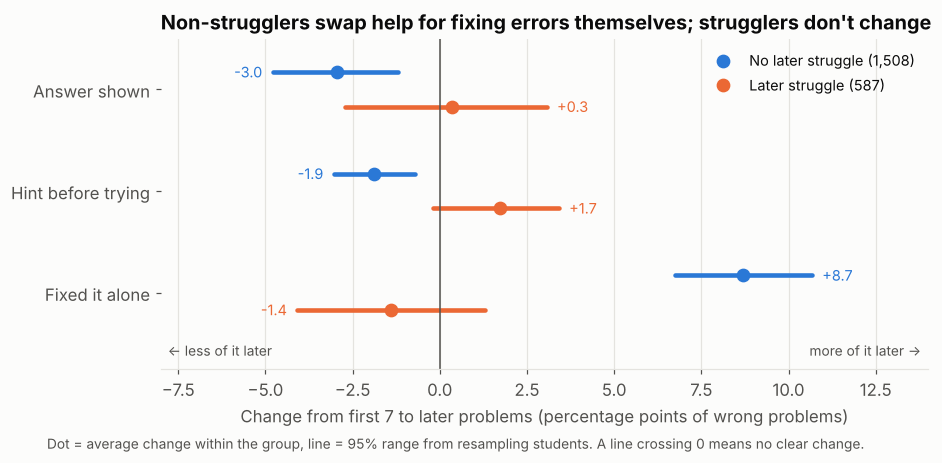

In [12]:
# fig12: the same table as a picture
meas = [("bottom_out_change", "Answer shown"), ("hint_first_change", "Hint before trying"), ("fixed_alone_change", "Fixed it alone")]
fig, ax = plt.subplots(figsize=(9, 3.9))
yb = np.array([2.0, 1.0, 0.0])
for g, off in [(0, 0.17), (1, -0.17)]:
    d = per_hist[per_hist.later_struggle == g]
    for y, (col, nm) in zip(yb, meas):
        m, lo, hi = boot_mean(d, col)
        ax.plot([100 * lo, 100 * hi], [y + off] * 2, color=C[g], lw=3, solid_capstyle="round")
        ax.plot(100 * m, y + off, "o", ms=8, color=C[g], label=f"{LABELS[g]} ({len(d):,})" if y == 2 else None)
        if m < 0: ax.text(100 * lo - 0.3, y + off, f"{100 * m:+.1f}", va="center", ha="right", fontsize=9.5, color=C[g])
        else: ax.text(100 * hi + 0.3, y + off, f"{100 * m:+.1f}", va="center", fontsize=9.5, color=C[g])
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(yb, [nm for _, nm in meas]); ax.grid(axis="y", visible=False)
ax.set_xlim(-8, 14); ax.set_xlabel(f"Change from first {K} to later problems (percentage points of wrong problems)")
ax.text(-7.8, -0.62, "← less of it later", fontsize=9, color=INK2); ax.text(13.8, -0.62, "more of it later →", fontsize=9, color=INK2, ha="right")
ax.set_ylim(-0.75, 2.5); ax.legend(loc="upper right", fontsize=9.5)
ax.set_title("Non-strugglers swap help for fixing errors themselves; strugglers don't change")
save_fig(fig, "fig12_change_within_each_group", "Dot = average change within the group, line = 95% range from resampling students. A line crossing 0 means no clear change.")

**Reading it.** A range that doesn't include 0 means a real change.

- **No later struggle:** answer-clicking falls about 3 points and hint-before-trying about 2, while *fixed it alone* rises about 9. These students swapped help for fixing their own errors.
- **Later struggle:** no change on any of the three measures. Every range includes 0.

So for Part 1 of RQ2: reliance fades with practice, modestly, but **only for students who don't later struggle**. Part 2, whether the difference between the groups is real at the same starting level, is next.

## 6. Easy-to-read test: strugglers vs others, same early score

Students who start badly have more room to improve, so they tend to change more whoever they are, and most strugglers start badly. A plain comparison of the two groups is therefore blurred: strugglers borrow the large change typical of their low-early-score group, which can hide how they differ from students who started at the same level. So we compare strugglers with others **within each early score** (0 to 6 right), then combine the within-score differences.

For uncertainty we **resample whole students** 2,000 times. One student can have several histories (one per skill), and those echo each other; resampling histories would make the ranges too narrow.

In [13]:
def same_score_difference(df, value_col, n_boot=2000, seed=612):
    # Difference in change (struggle minus not) within early-score groups, combined;
    # 95% range from resampling whole students. Row 0 of W is the real sample.
    rng = np.random.default_rng(seed)
    students = df.userId.unique(); idx = pd.Series(np.arange(len(students)), index=students)
    W = np.vstack([np.ones(len(students)),
                   rng.multinomial(len(students), np.full(len(students), 1 / len(students)), size=n_boot)])
    num = np.zeros(n_boot + 1); den = np.zeros(n_boot + 1)
    for _, grp in df.groupby("early_score"):
        u = idx[grp.userId].to_numpy(); s = (grp.later_struggle == 1).to_numpy(); v = grp[value_col].to_numpy()
        tot = lambda m, x: W @ np.bincount(u[m], weights=x[m], minlength=len(students))
        n1, n0 = tot(s, np.ones(len(u))), tot(~s, np.ones(len(u)))
        m1, m0 = tot(s, v) / np.where(n1 > 0, n1, 1), tot(~s, v) / np.where(n0 > 0, n0, 1)
        w = np.where((n1 > 0) & (n0 > 0), n1 * n0 / (n1 + n0), 0)
        num += w * (m1 - m0); den += w
    est = num / den * 100
    lo, hi = np.percentile(est[1:], [2.5, 97.5])
    return est[0], lo, hi

rows = []
for m, name in [("bottom_out_change", "Answer-clicking"), ("hint_first_change", "Hint before trying")]:
    raw = (per_hist[per_hist.later_struggle == 1][m].mean() - per_hist[per_hist.later_struggle == 0][m].mean()) * 100
    est, lo, hi = same_score_difference(per_hist, m)
    rows.append({"measure": name, "difference in change, everyone together": raw,
                 "difference in change, same early score": est, "95% low": lo, "95% high": hi})
pd.DataFrame(rows).round(1)

,measure,"difference in change, everyone together","difference in change, same early score",95% low,95% high
0,Answer-clicking,3.3,8.0,4.1,11.9
1,Hint before trying,3.6,3.2,0.6,5.6


Read "difference in change" as: how much more the strugglers' share went up (or less it went down) than other students', in percentage points.

- **Answer-clicking:** at the same early score, strugglers' share changes about **8 points** more than others' (they don't reduce it; others do). The range is well above zero.
- **Hint before trying:** about **3 points**, range above zero.

### 6b. Does the gap differ between early-score groups?

The +8 above is a **weighted average** of seven separate comparisons, one for each early score. How each row is built:

- **Strugglers' change / Others' change:** the average of each history's own change (later minus early), within that early-score group.
- **Gap:** strugglers' change minus others' change.
- **Weight = strugglers × others ÷ (strugglers + others).** A comparison is only as trustworthy as its smaller group, so 68 strugglers against 433 others counts less than its 501 total suggests.

There is no group for a score of 7 out of 7. Those students were never stuck early, so they have no early share and no change. Only 2 of those 161 histories struggled later anyway.

The gaps vary between groups (roughly 4 to 18 points). Two formal tests check whether that variation is more than chance: a Wald test that all gaps are equal, and a test for a linear trend across early scores.

In [14]:
from scipy.stats import chi2

def bucket_check(df, value_col, n_boot=4000, seed=612):
    rng = np.random.default_rng(seed)
    students = df.userId.unique(); idx = pd.Series(np.arange(len(students)), index=students)
    W = np.vstack([np.ones(len(students)),
                   rng.multinomial(len(students), np.full(len(students), 1 / len(students)), size=n_boot)])
    scores = sorted(df.early_score.unique()); gaps, wts, rows = [], [], []
    for es in scores:
        grp = df[df.early_score == es]
        u = idx[grp.userId].to_numpy(); s = (grp.later_struggle == 1).to_numpy(); v = 100 * grp[value_col].to_numpy()
        tot = lambda m, x: W @ np.bincount(u[m], weights=x[m], minlength=len(students))
        n1, n0 = tot(s, np.ones(len(u))), tot(~s, np.ones(len(u)))
        m1, m0 = tot(s, v) / np.maximum(n1, 1e-9), tot(~s, v) / np.maximum(n0, 1e-9)
        gaps.append(m1 - m0); wts.append(n1 * n0 / (n1 + n0))
        rows.append({"early score": es, "strugglers": s.sum(), "others": (~s).sum(),
                     "strugglers' change": m1[0], "others' change": m0[0], "gap": (m1 - m0)[0],
                     "95% range": f"{np.percentile((m1 - m0)[1:], 2.5):.1f} to {np.percentile((m1 - m0)[1:], 97.5):.1f}",
                     "weight": wts[-1][0]})
    G, Wt = np.array(gaps).T, np.array(wts).T
    table = pd.DataFrame(rows); table["weight %"] = 100 * table.weight / table.weight.sum()

    # Test 1: could all gaps be one number? (adjacent differences = 0, bootstrap covariance)
    C = np.eye(len(scores))[1:] - np.eye(len(scores))[:-1]
    d = C @ G[0]; V = np.cov((G[1:] @ C.T).T); wald = d @ np.linalg.solve(V, d)
    # Test 2: does the gap grow with early score? (weighted slope)
    x = np.array(scores, float)
    def slope(g, w):
        xm = (w * x).sum() / w.sum(); return (w * (x - xm) * g).sum() / (w * (x - xm) ** 2).sum()
    sl = np.array([slope(G[i], Wt[i]) for i in range(len(G))])
    tests = pd.DataFrame([
        {"test": "All gaps equal (Wald)", "result": f"chi2 = {wald:.1f}, df = {len(d)}", "p": chi2.sf(wald, len(d))},
        {"test": "Gap grows with early score", "result": f"{sl[0]:+.1f} per point [{np.percentile(sl[1:], 2.5):.1f}, {np.percentile(sl[1:], 97.5):.1f}]",
         "p": 2 * min((sl[1:] <= 0).mean(), (sl[1:] >= 0).mean())}])
    return table.round(1), tests.round(3)

table, tests = bucket_check(per_hist, "bottom_out_change")
display(table); tests

,early score,strugglers,others,strugglers' change,others' change,gap,95% range,weight,weight %
0,0,126,49,-7.8,-20.7,12.9,2.0 to 24.0,35.3,9.9
1,1,75,91,-7.3,-11.8,4.4,-5.9 to 15.1,41.1,11.5
2,2,86,134,0.1,-5.2,5.3,-2.7 to 13.7,52.4,14.6
3,3,114,228,-0.2,-4.3,4.1,-4.2 to 12.2,76.0,21.2
4,4,95,320,5.0,-2.1,7.1,-2.0 to 16.0,73.3,20.5
5,5,68,433,12.6,-0.0,12.6,4.3 to 20.7,58.8,16.4
6,6,23,253,18.1,0.0,18.1,2.0 to 33.8,21.1,5.9


,test,result,p
0,All gaps equal (Wald),"chi2 = 5.4, df = 6",0.496
1,Gap grows with early score,"+1.0 per point [-1.2, 3.0]",0.352


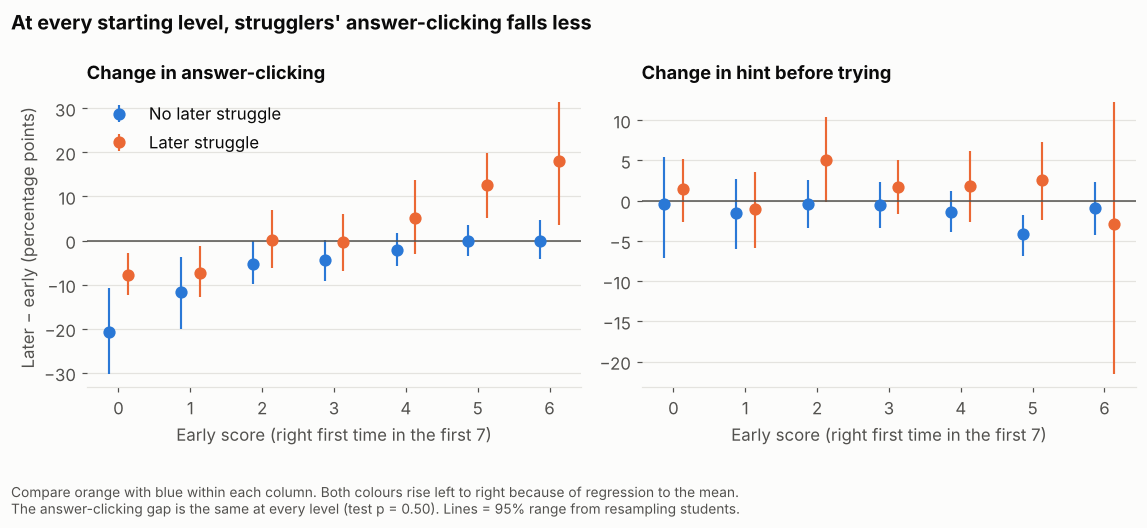

In [15]:
# fig4: change by early score, both groups (groups with fewer than 15 histories hidden)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for ax, (col, title) in zip(axes, [("bottom_out_change", "Change in answer-clicking"), ("hint_first_change", "Change in hint before trying")]):
    for g, off in [(0, -0.13), (1, 0.13)]:
        pts = np.array([(e, *boot_mean(d, col, 1000)) for e in sorted(per_hist.early_score.unique())
                        for d in [per_hist[(per_hist.later_struggle == g) & (per_hist.early_score == e)]] if len(d) >= 15])
        pts[:, 1:] *= 100
        ax.errorbar(pts[:, 0] + off, pts[:, 1], yerr=[pts[:, 1] - pts[:, 2], pts[:, 3] - pts[:, 1]], fmt="o", color=C[g],
                    ms=7, elinewidth=1.4, capsize=0, label=LABELS[g])
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xlabel(f"Early score (right first time in the first {K})"); ax.set_title(title, fontsize=12)
    ax.set_xticks(range(0, K)); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Later − early (percentage points)")
axes[0].legend(loc="upper left")
fig.suptitle("At every starting level, strugglers' answer-clicking falls less", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save_fig(fig, "fig4_by_early_score", "Compare orange with blue within each column. Both colours rise left to right because of regression to the mean.\n"
         f"The answer-clicking gap is the same at every level (test p = {tests.p.iloc[0]:.2f}). Lines = 95% range from resampling students.")

**Reading it**

- Every gap is positive, but most of the individual ranges are wide. The score-6 group has only 23 strugglers, and its range runs from about 2 to 34.
- Neither test finds a difference: p ≈ 0.5 for "all equal" and p ≈ 0.35 for a trend. The ups and downs are about what chance alone would produce.
- So the honest summary is **about 8 points at every starting level**. Averaging hides nothing real here.
- One reason the high groups are especially noisy: a student who scored 6 out of 7 had just **one** wrong early problem, so their early share is either 0% or 100%.

## 7. Main test: rank-based ANCOVA, the same family as RQ1

RQ1's main model is a **Quade-type ANCOVA**: it turns the outcome and the continuous covariates into **ranks** (1 = smallest), then runs a regression with skill fixed effects and tests one term with a partial F-test. Ranks make it robust to skewed values and outliers.

For RQ2 we use the same machinery with the roles arranged for our question:

> rank(change in reliance) ~ **rank(later % correct)** + rank(early score) + rank(scaffold share) + rank(format shares) + rank(item easiness) + skill

The test asks: **after accounting for everything RQ1 accounts for, is later performance linked to how much a student's reliance changed?** It uses the continuous later percentage, so no 50% cut-off is involved.

From section 6, the expected sign of the coefficient on later % correct is **negative**: higher later performance should go with a *bigger drop* in reliance (a more negative change), and struggling with no drop or a rise.

In [16]:
COVARIATES = ["early_score", "early_scaffold_share", "early_algebra_share", "early_choose_1_share",
              "early_fill_in_1_share", "mean_early_item_easiness"]

def ranks(x):
    return pd.Series(x).rank(method="average").to_numpy()

def quade_test(df, outcome, focal="later_percent_correct", extra=()):
    # Partial F-test for `focal` in a rank regression with RQ1's covariates and skill fixed effects.
    skills = pd.get_dummies(df.skill, drop_first=True, dtype=float).to_numpy()
    base = np.column_stack([np.ones(len(df))] + [ranks(df[c]) for c in [*COVARIATES, *extra]] + [skills])
    full = np.column_stack([base, ranks(df[focal])])
    y = ranks(df[outcome])
    def fit(X):
        b, *_ = np.linalg.lstsq(X, y, rcond=None); r = y - X @ b
        return r @ r, b
    rss0, _ = fit(base); rss1, b = fit(full)
    df_den = len(y) - np.linalg.matrix_rank(full)
    F = (rss0 - rss1) / (rss1 / df_den)
    return {"n": len(y), "rank coefficient on later %": b[-1], "F": F, "p": f_dist.sf(F, 1, df_den)}

results = []
for m, name in [("bottom_out", "Answer-clicking"), ("hint_first", "Hint before trying")]:
    results.append({"measure": name, "model": "RQ1 covariates", **quade_test(per_hist, f"{m}_change")})
    results.append({"measure": name, "model": "+ early level of the measure",
                    **quade_test(per_hist, f"{m}_change", extra=(f"{m}_early",))})
out = pd.DataFrame(results)
out["p"] = out["p"].map(lambda v: f"{v:.1e}")
out.round(3)

,measure,model,n,rank coefficient on later %,F,p
0,Answer-clicking,RQ1 covariates,2095,-0.104,17.534,2.9e-05
1,Answer-clicking,+ early level of the measure,2095,-0.215,110.507,3.3e-25
2,Hint before trying,RQ1 covariates,2095,-0.107,23.806,1.1e-06
3,Hint before trying,+ early level of the measure,2095,-0.123,49.550,2.6e-12


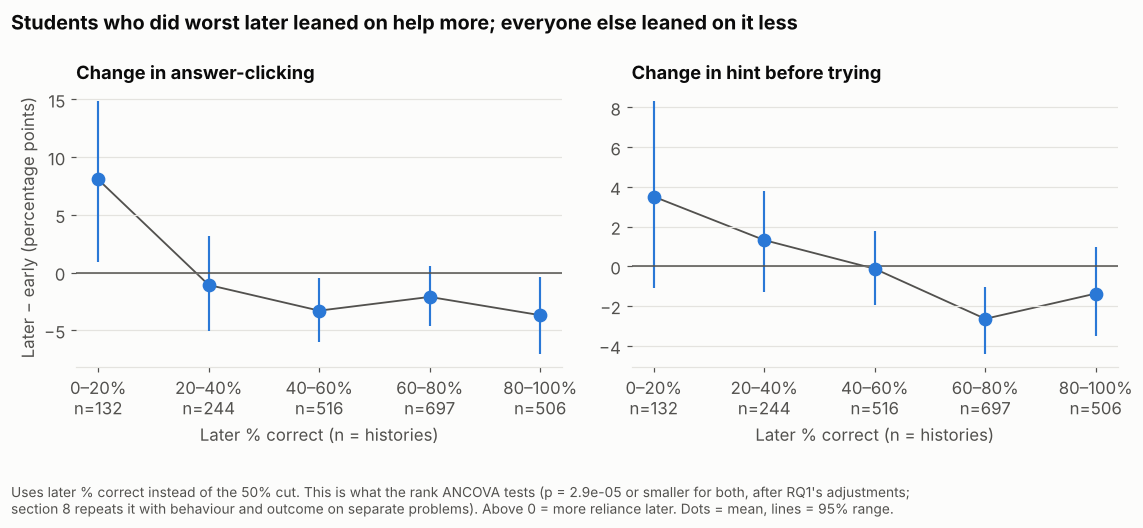

In [17]:
# fig5: what the rank ANCOVA tests, shown with later % in five bands
bins = [0, 20, 40, 60, 80, 100.01]; bands = ["0–20%", "20–40%", "40–60%", "60–80%", "80–100%"]
per_hist["later_band"] = pd.cut(per_hist.later_percent_correct, bins, labels=bands, right=False)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for ax, (col, title) in zip(axes, [("bottom_out_change", "Change in answer-clicking"), ("hint_first_change", "Change in hint before trying")]):
    pts = np.array([(i, *boot_mean(per_hist[per_hist.later_band == b], col, 1000), (per_hist.later_band == b).sum()) for i, b in enumerate(bands)])
    pts[:, 1:4] *= 100
    ax.plot(pts[:, 0], pts[:, 1], color=INK2, lw=1.2, zorder=1)
    ax.errorbar(pts[:, 0], pts[:, 1], yerr=[pts[:, 1] - pts[:, 2], pts[:, 3] - pts[:, 1]], fmt="o", color=C[0], ms=8, elinewidth=1.4, capsize=0, zorder=2)
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xticks(range(len(bands)), [f"{b}\nn={int(q[4])}" for b, q in zip(bands, pts)])
    ax.set_xlabel("Later % correct (n = histories)"); ax.set_title(title, fontsize=12); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Later − early (percentage points)")
fig.suptitle("Students who did worst later leaned on help more; everyone else leaned on it less", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
p_main = max(r["p"] for r in results if r["model"] == "RQ1 covariates")
save_fig(fig, "fig5_by_later_performance", f"Uses later % correct instead of the 50% cut. This is what the rank ANCOVA tests (p = {p_main:.1e} or smaller for both, after RQ1's adjustments;\n"
         "section 8 repeats it with behaviour and outcome on separate problems). Above 0 = more reliance later. Dots = mean, lines = 95% range.")

Both measures have a **negative** coefficient with very small p-values. After RQ1's adjustments, students who do better later are the ones whose reliance on help **dropped** more.

**Why the second row?** A student who starts at 90% answer-clicking can only go down; one who starts at 0% can only go up. So change partly depends on the starting level, a pull towards the middle called **regression to the mean**. Adding the early level of the measure as a covariate removes that. The link with later performance gets *stronger*, not weaker, so it isn't an artefact of starting points.

## 8. Robustness: no problem used twice

There's a weak point in sections 5–7. "Later struggle" is decided from problems 8 onward, and the "later" behaviour is measured on **the same problems**. So two things could create a difference without any real change in habits:
- **Harder later problems** make a student get more wrong (towards "struggle") *and* click through to answers more.
- **A bad patch** (an off day) does the same.

**The fix:** split the later problems in two. Measure behaviour on the **first half** of the later problems; decide struggle only from the **second half**. Now no problem is used twice. Then also adjust for how hard each half's problems were.

```
problems:   1 ... 7  |  8 ... middle  |  middle+1 ... end
role:       early    |  behaviour (B) |  outcome (O): decides struggle
```

In [18]:
item_easiness = episode.groupby("problemId").first_correct.mean()
att = attempts.merge(pop[["userId", "skill", "n_attempts"]], on=["userId", "skill"])
att["ease"] = att.problemId.map(item_easiness)
att["mid"] = K + np.ceil((att.n_attempts - K) / 2)
att["part"] = np.select([att.skill_attempt <= K, att.skill_attempt <= att.mid], ["early", "B"], "O")

outcome_O = (att[att.part == "O"].groupby(["userId", "skill"])
             .agg(O_pct=("first_correct", lambda x: 100 * x.mean()), O_ease=("ease", "mean"), n_O=("part", "size"))
             .reset_index())
outcome_O["O_struggle"] = (outcome_O.O_pct < 50).astype(int)
B_ease = att[att.part == "B"].groupby(["userId", "skill"]).ease.mean().rename("B_ease").reset_index()

stuck_s = att[att.hint_item & (att.state != "CFA") & att.part.isin(["early", "B"])].copy()
stuck_s["bottom_out"] = (stuck_s.state == "BOH").astype(float)
stuck_s["hint_first"] = (stuck_s.state == "HINT-FIRST").astype(float)
split = stuck_s.groupby(["userId", "skill", "part"])[["bottom_out", "hint_first"]].mean().unstack("part").dropna()
split.columns = [f"{m}_{w}" for m, w in split.columns]
split = (split.reset_index()
         .merge(pop.drop(columns=["later_struggle", "later_percent_correct"]), on=["userId", "skill"])
         .merge(outcome_O, on=["userId", "skill"]).merge(B_ease, on=["userId", "skill"]))
split["bottom_out_change"] = split.bottom_out_B - split.bottom_out_early
split["hint_first_change"] = split.hint_first_B - split.hint_first_early
split["later_struggle"] = split.O_struggle            # so the section 6 function can be reused

print(f"{len(split):,} histories; outcome decided from a median of {split.n_O.median():.0f} problems; "
      f"struggle rate {split.O_struggle.mean():.1%}")
split.groupby("O_struggle")[["bottom_out_early", "bottom_out_B", "hint_first_early", "hint_first_B"]].mean().rename(index=LABELS).round(3)

2,018 histories; outcome decided from a median of 6 problems; struggle rate 20.3%


,bottom_out_early,bottom_out_B,hint_first_early,hint_first_B
O_struggle,,,,
No later struggle,0.271,0.245,0.088,0.076
Later struggle,0.418,0.433,0.110,0.122


In [19]:
rows, robust = [], []
for m, name in [("bottom_out", "Answer-clicking"), ("hint_first", "Hint before trying")]:
    est0, lo0, hi0 = same_score_difference(per_hist, f"{m}_change")
    est1, lo1, hi1 = same_score_difference(split, f"{m}_change")
    q_plain = quade_test(split, f"{m}_change", focal="O_pct")
    q_ease = quade_test(split, f"{m}_change", focal="O_pct", extra=("B_ease", "O_ease"))
    rows.append({"measure": name,
                 "original: same-score difference": f"{est0:+.1f} [{lo0:.1f}, {hi0:.1f}]",
                 "no problem used twice": f"{est1:+.1f} [{lo1:.1f}, {hi1:.1f}]",
                 "ANCOVA p (outcome half)": f"{q_plain['p']:.1e}",
                 "ANCOVA p (+ problem difficulty)": f"{q_ease['p']:.1e}"})
    robust.append({"measure": name, "orig": (est0, lo0, hi0), "split": (est1, lo1, hi1),
                   "p_orig": quade_test(per_hist, f"{m}_change")["p"], "p_split": q_ease["p"]})
pd.DataFrame(rows)

,measure,original: same-score difference,no problem used twice,ANCOVA p (outcome half),ANCOVA p (+ problem difficulty)
0,Answer-clicking,"+8.0 [4.1, 11.9]","+8.0 [3.3, 12.4]",2.0e-03,1.8e-02
1,Hint before trying,"+3.2 [0.6, 5.6]","+1.4 [-1.3, 4.3]",1.2e-02,1.2e-02


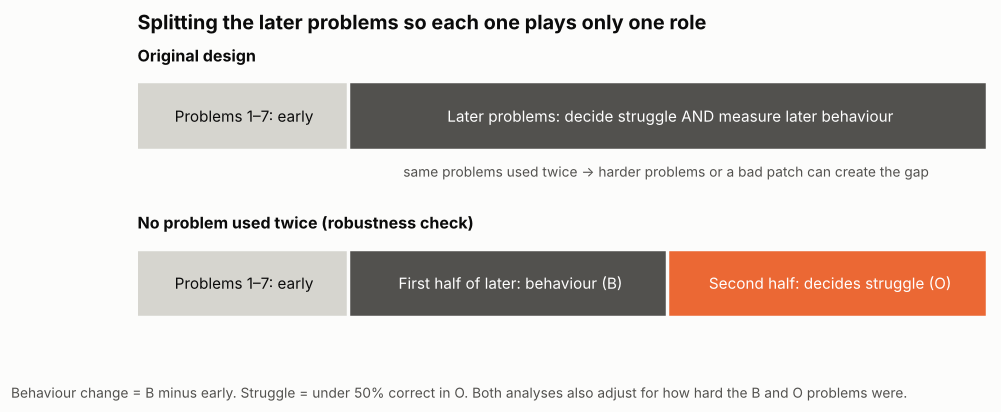

In [20]:
# fig9: which problems play which role
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.axis("off"); ax.set_xlim(0, 100); ax.set_ylim(0, 10)
def box(x0, x1, y, txt, col, tc="white"):
    ax.add_patch(plt.Rectangle((x0, y), x1 - x0 - 0.6, 2.2, color=col))
    ax.text((x0 + x1) / 2, y + 1.1, txt, ha="center", va="center", fontsize=10, color=tc)
ax.text(0, 9.2, "Original design", fontweight="bold", fontsize=10.5)
box(0, 25, 6.2, f"Problems 1–{K}: early", "#d6d5cf", INK)
box(25, 100, 6.2, "Later problems: decide struggle AND measure later behaviour", INK2)
ax.text(62, 5.2, "same problems used twice → harder problems or a bad patch can create the gap", ha="center", fontsize=9, color=INK2)
ax.text(0, 3.4, "No problem used twice (robustness check)", fontweight="bold", fontsize=10.5)
box(0, 25, 0.4, f"Problems 1–{K}: early", "#d6d5cf", INK)
box(25, 62.5, 0.4, "First half of later: behaviour (B)", INK2)
box(62.5, 100, 0.4, "Second half: decides struggle (O)", C[1])
ax.set_title("Splitting the later problems so each one plays only one role")
save_fig(fig, "fig9_window_split", "Behaviour change = B minus early. Struggle = under 50% correct in O. Both analyses also adjust for how hard the B and O problems were.")

,ERR-SELF_B,ERR-SELF_early,ERR-HINT_B,ERR-HINT_early,HINT-FIRST_B,HINT-FIRST_early,BOH_B,BOH_early
O_struggle,,,,,,,,
No later struggle,56.1,49.5,11.8,14.6,7.6,8.8,24.5,27.1
Later struggle,35.3,37.5,9.1,9.7,12.2,11.0,43.3,41.8


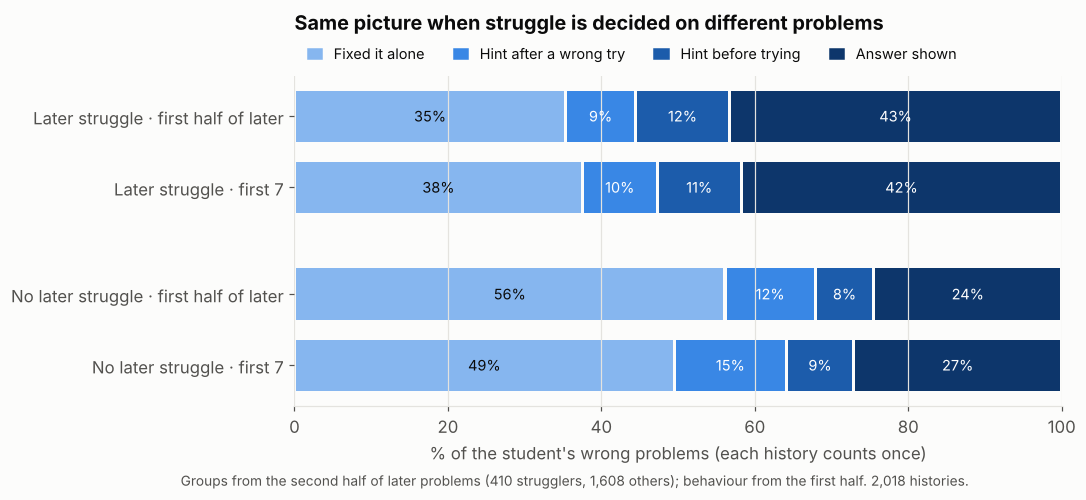

In [21]:
# fig10: fig2 redone with no problem used twice
split_shares, comp2 = state_shares(stuck_s.merge(outcome_O[["userId", "skill", "O_struggle"]], on=["userId", "skill"]), "part", "O_struggle")
nn = split_shares.O_struggle.value_counts()
composition_chart(comp2, [(1, "B"), (1, "early"), (0, "B"), (0, "early")],
                  [f"{LABELS[g]} · {'first half of later' if w == 'B' else f'first {K}'}" for g, w in [(1, "B"), (1, "early"), (0, "B"), (0, "early")]],
                  "Same picture when struggle is decided on different problems", "fig10_what_students_do_split",
                  f"Groups from the second half of later problems ({nn[1]:,} strugglers, {nn[0]:,} others); behaviour from the first half. {len(split_shares):,} histories.")
comp2.rename(index=LABELS).round(1)

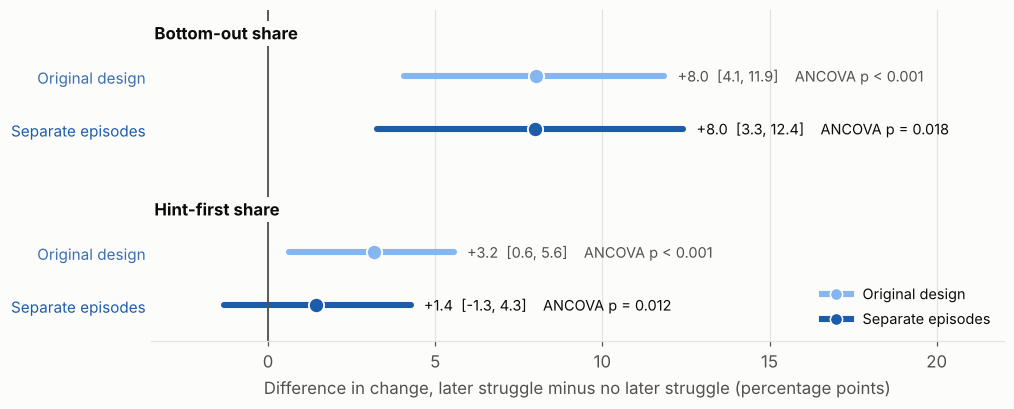

In [22]:
# fig11: original vs split estimates, read from the table above (`robust`)
DESIGN_COL = {"orig": "#86b6ef", "split": "#1c5cab"}       # light = original design, dark = separate episodes
DESIGN_NAME = {"orig": "Original design", "split": "Separate episodes"}
MEASURE_NAME = {"Answer-clicking": "Bottom-out share", "Hint before trying": "Hint-first share"}
fmt_p = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

fig, ax = plt.subplots(figsize=(10, 3.9))
ys = {("Answer-clicking", "orig"): 3.2, ("Answer-clicking", "split"): 2.6,
      ("Hint before trying", "orig"): 1.2, ("Hint before trying", "split"): 0.6}
for r in robust:
    for kind in ("orig", "split"):
        e, lo, hi = r[kind]; y = ys[(r["measure"], kind)]; col = DESIGN_COL[kind]
        p = r["p_orig"] if kind == "orig" else r["p_split"]
        ax.plot([lo, hi], [y, y], color=col, lw=4, solid_capstyle="round")
        ax.plot(e, y, "o", ms=10, color=col, mec="white", mew=1.2, zorder=3)
        ax.text(hi + 0.4, y, f"{e:+.1f}  [{lo:.1f}, {hi:.1f}]    ANCOVA {fmt_p(p)}", va="center",
                fontsize=9.5, color=INK if kind == "split" else INK2)
ax.axvline(0, color=INK2, lw=1.2)
ax.set_yticks(list(ys.values()), [DESIGN_NAME[k] for _, k in ys], fontsize=10)
for tick, (_, k) in zip(ax.get_yticklabels(), ys): tick.set_color(DESIGN_COL[k] if k == "split" else "#3a6fb0")
ax.tick_params(axis="y", length=0)
for y, m in [(3.62, "Answer-clicking"), (1.62, "Hint before trying")]:
    ax.text(-3.4, y, MEASURE_NAME[m], fontweight="bold", fontsize=11, color=INK,
            bbox=dict(fc=SURF, ec="none", pad=1.5), zorder=4)
ax.set_xlim(-3.5, 22); ax.set_ylim(0.2, 3.95); ax.grid(axis="y", visible=False)
ax.set_xlabel("Difference in change, later struggle minus no later struggle (percentage points)")
ax.legend(handles=[plt.Line2D([0], [0], color=DESIGN_COL[k], lw=4, marker="o", ms=8, mec="white", label=DESIGN_NAME[k])
                   for k in ("orig", "split")], loc="lower right", fontsize=9.5)
save_fig(fig, "fig11_split_robustness")

**What survives**

- **Answer-clicking: fully.** With no problem used twice, strugglers' answer-clicking still falls about 8 points less than comparable students' (range clear of 0), and the rank-based ANCOVA still finds the link after adjusting for how hard both halves were. This is RQ2's headline.
- **Hint before trying: partly.** The group difference shrinks to about +1 point and its range now includes 0. The ANCOVA still finds a small link (p ≈ 0.01) after the difficulty adjustment. So some of the earlier +3 points came from reusing the same problems. Report it as supporting evidence, not a headline.

What no split can fix is **direction**: whether relying on answers leads to struggle, or struggle leads to relying on answers. Write "is associated with", never "causes".

## 9. Networks: a pre-specified test that did not hold up

The project brief phrases RQ2 in network terms. In the earlier exploratory analysis (3-problem window), networks built from **stuck problems only**, with **back-to-back problems only** and **one vote per history**, suggested that strugglers become more repetitive. The "average of the four repeat loops" summary was chosen *after* looking at the data, so it needed a fair test.

Running the same summary on RQ1's 7-problem window, decided **in advance**, is that test. (It isn't fully independent: these histories are a subset of the earlier ones, but the windows differ.) If the original pattern were real, the average loop difference here should be clearly positive, as it was in the exploratory run (+8.4 points).

In [23]:
STUCK = ["ERR-SELF", "ERR-HINT", "HINT-FIRST", "BOH"]; pos = {st: i for i, st in enumerate(STUCK)}

def history_votes(att):
    # Back-to-back stuck transitions within the same window; each history gives one vote per window.
    st = att[att.hint_item & att.state.isin(STUCK)].sort_values(["userId", "skill", "skill_attempt"]).copy()
    g = st.groupby(["userId", "skill"])
    st["to_state"], st["to_window"] = g.state.shift(-1), g.window.shift(-1)
    st["gap"] = g.skill_attempt.shift(-1) - st.skill_attempt
    tr = st[st.to_state.notna() & (st.window == st.to_window) & (st.gap == 1)].copy()
    tr["history"] = tr.groupby(["userId", "skill"]).ngroup()
    tr["edge"] = tr.state.map(pos) * 4 + tr.to_state.map(pos)
    tr["later"] = (tr.window == "later").astype(int)
    counts = np.zeros((tr.history.max() + 1, 2, 16))
    np.add.at(counts, (tr.history.to_numpy(), tr.later.to_numpy(), tr.edge.to_numpy()), 1)
    totals = counts.sum(axis=2, keepdims=True)
    votes = np.divide(counts, totals, out=np.zeros_like(counts), where=totals > 0)
    return tr, votes, tr.groupby("history").later_struggle.first().sort_index().to_numpy()

tr, votes, hist_label = history_votes(attempts)

def networks(v, lab):
    out = {}
    for grp in (0, 1):
        for w in (0, 1):
            m = v[lab == grp, w].sum(axis=0).reshape(4, 4)
            rs = m.sum(axis=1, keepdims=True)
            out[(grp, w)] = m / np.where(rs > 0, rs, np.nan)
    return out

def summaries(n):
    did = ((n[(1, 1)] - n[(1, 0)]) - (n[(0, 1)] - n[(0, 0)])).ravel()
    loops = np.nanmean(did[[0, 5, 10, 15]])                                  # pre-specified: average repeat loop
    overall = np.nanmean(np.abs(n[(1, 1)] - n[(1, 0)])) - np.nanmean(np.abs(n[(0, 1)] - n[(0, 0)]))  # overall network change
    return loops, overall, did

nets = networks(votes, hist_label)
loops, overall, did = summaries(nets)
rng = np.random.default_rng(1); perm_loops, perm_overall = [], []
for _ in range(2000):
    a_, b_, _c = summaries(networks(votes, rng.permutation(hist_label)))
    perm_loops.append(a_); perm_overall.append(b_)

print(f"{len(tr):,} back-to-back stuck transitions from {tr.history.nunique():,} histories")
print(f"Average repeat-loop difference in change: {loops * 100:+.1f} points, "
      f"permutation p = {(np.sum(np.abs(perm_loops) >= abs(loops)) + 1) / 2001:.3f}")
print(f"Overall network change, strugglers minus others: {overall * 100:+.2f} points, "
      f"permutation p = {(np.sum(np.abs(perm_overall) >= abs(overall)) + 1) / 2001:.3f}")
pd.DataFrame({"repeat loop": [f"{x} → {x}" for x in STUCK],
              "strugglers early": [nets[(1, 0)][pos[x], pos[x]] for x in STUCK],
              "strugglers later": [nets[(1, 1)][pos[x], pos[x]] for x in STUCK],
              "others early": [nets[(0, 0)][pos[x], pos[x]] for x in STUCK],
              "others later": [nets[(0, 1)][pos[x], pos[x]] for x in STUCK],
              "difference in change (points)": did[[0, 5, 10, 15]] * 100}).round(2)

11,307 back-to-back stuck transitions from 1,856 histories
Average repeat-loop difference in change: +0.0 points, permutation p = 0.999
Overall network change, strugglers minus others: -1.97 points, permutation p = 0.161


,repeat loop,strugglers early,strugglers later,others early,others later,difference in change (points)
0,ERR-SELF → ERR-SELF,0.77,0.75,0.77,0.78,-2.61
1,ERR-HINT → ERR-HINT,0.33,0.33,0.33,0.28,4.40
2,HINT-FIRST → HINT-FIRST,0.55,0.60,0.30,0.44,-7.99
3,BOH → BOH,0.74,0.76,0.62,0.58,6.22


In [24]:
# The exploratory version: the same summary on the 3-problem window (RQ1's k3 population, at least 6 problems)
pop3 = handoff["k3_population"]
att3 = episode.sort_values(["userId", "skill", "start_time", "episode_row_order"], kind="mergesort").copy()
att3["skill_attempt"] = att3.groupby(["userId", "skill"]).cumcount() + 1
att3 = att3.merge(pop3[["userId", "skill", "later_struggle"]], on=["userId", "skill"])
att3["window"] = np.where(att3.skill_attempt <= 3, "early", "later")
att3["hint_item"] = ~att3.problemId.isin(scaffold_items)
tr3, votes3, label3 = history_votes(att3)
loops3, _, did3 = summaries(networks(votes3, label3))
print(f"3-problem window: {tr3.history.nunique():,} histories; average repeat-loop difference {loops3 * 100:+.1f} points")
print(f"{K}-problem window: average repeat-loop difference {loops * 100:+.1f} points")

3-problem window: 4,297 histories; average repeat-loop difference +8.4 points
7-problem window: average repeat-loop difference +0.0 points


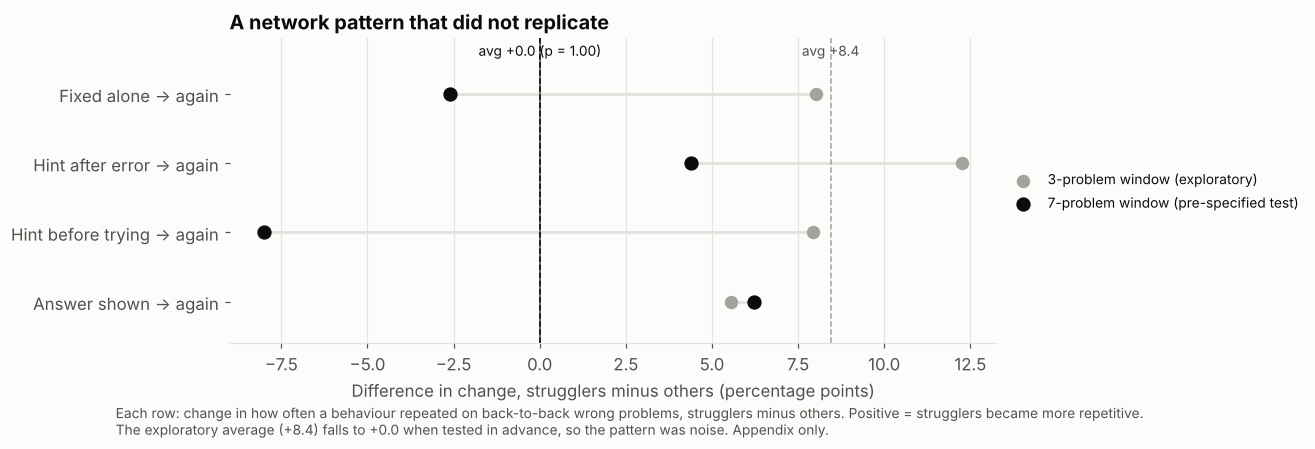

In [25]:
# fig8: the network pattern that did not replicate
loop_names = ["Fixed alone → again", "Hint after error → again", "Hint before trying → again", "Answer shown → again"]
k3v, k7v = did3[[0, 5, 10, 15]] * 100, did[[0, 5, 10, 15]] * 100
p_loops = (np.sum(np.abs(perm_loops) >= abs(loops)) + 1) / 2001
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(4)[::-1]
for yi, a3, a7 in zip(y, k3v, k7v):
    ax.plot([a3, a7], [yi, yi], color=GRID, lw=2, zorder=1)
ax.scatter(k3v, y, s=60, color="#a3a29b", zorder=2, label="3-problem window (exploratory)")
ax.scatter(k7v, y, s=70, color=INK, zorder=3, label=f"{K}-problem window (pre-specified test)")
ax.axvline(0, color=INK2, lw=1)
ax.axvline(k3v.mean(), color="#a3a29b", lw=1, ls="--"); ax.axvline(k7v.mean(), color=INK, lw=1, ls="--")
ax.text(k3v.mean(), 3.55, f"avg {k3v.mean():+.1f}", color=INK2, fontsize=9, ha="center")
ax.text(k7v.mean(), 3.55, f"avg {k7v.mean():+.1f} (p = {p_loops:.2f})", color=INK, fontsize=9, ha="center")
ax.set_yticks(y, loop_names); ax.set_ylim(-0.6, 3.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("Difference in change, strugglers minus others (percentage points)")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)
ax.set_title("A network pattern that did not replicate")
save_fig(fig, "fig8_network_not_replicated", "Each row: change in how often a behaviour repeated on back-to-back wrong problems, strugglers minus others. Positive = strugglers became more repetitive.\n"
         f"The exploratory average ({k3v.mean():+.1f}) falls to {k7v.mean():+.1f} when tested in advance, so the pattern was noise. Appendix only.")

**Result.** The average loop difference is about **0**, with p close to 1. The overall network change measure doesn't differ between groups either.

Only the answer → answer loop still leans the same way (strugglers' stays steady, others' drops), which matches the rate result in sections 5–7. The hint-before-trying loop now goes the *other* way.

**Why it is reported.** "An exploratory network pattern did not replicate on RQ1's selected window" is an honest, useful result. It shows the other RQ2 findings were checked rather than cherry-picked, and it explains why the firm conclusions come from the rate measures, not the networks.

## 10. What we can say, and what we can't

**Answer to RQ2 (draft for the report):**
> Using RQ1's selected 7-problem early window, students who did not later struggle reduced their reliance on bottom-out hints with practice (about 3 percentage points, 95% CI 1 to 5) and instead fixed more of their own errors without help (about 9 points more, 95% CI 7 to 11); students who later struggled showed neither change. At the same early score, the difference in change in bottom-out reliance was about 8 percentage points (95% CI 4 to 12), and it did not depend on the early score. This held when behaviour and outcome were measured on separate problems (about 8 points, 95% CI 3 to 12) and after adjusting for problem difficulty. In a rank-based ANCOVA with RQ1's covariates, higher later performance was associated with larger reductions in bottom-out reliance. Students who later struggled also tended to ask for hints before attempting a problem more over time, but this smaller effect weakened when behaviour and outcome were measured on separate problems. A transition-network pattern suggested by exploratory analysis (greater repetition among strugglers) did not replicate.

**Figures for the report** (all saved to `rq2_figures/` by the cells above)
- Main text: fig1 (why wrong problems only), fig9 (the split), fig10 or fig2 (what students do once stuck), fig12 (does reliance fade?), fig4 (same starting level), fig11 (does it survive the split?).
- Appendix: fig3 and fig5 (supporting views), fig6 (descriptive), fig8 (network check).

**What we can't claim**
- **Why.** Rising hint-before-trying could be disengagement, gaming the system or genuine confusion; the data shows behaviour, not intent.
- **Cause.** We can't tell whether persistent reliance leads to struggle or both come from something else, such as weaker prior knowledge.
- **Everyone.** RQ1's window needs at least 14 problems on a skill, and RQ2 additionally needs stuck problems in both windows (2,095 histories). Students who practise little, or rarely get things wrong, are under-represented.

**Limitations:** hint items only; later windows vary in length; the robustness split leaves a median of only 6 problems to decide struggle; item easiness in RQ1's covariates is computed from all attempts; one dataset from 2009–10.